# Análisis de resultados — Proyecto final HPC (malaria, autómata celular SIRS–SI)

Este notebook genera **todas** las figuras del informe a partir de:

- `outputs/times.csv` — una fila por ejecución (esquema de `AGENTS.md` §8).
- `outputs/metrics/*.csv` — series mensuales por paradigma, región y réplica (`AGENTS.md` §9).
- `outputs/experiments/` — experimentos puntuales (escalabilidad débil, scheduling, `lgamma`).
- `outputs/gpu/` — resultados de GPU (CuPy y kernel CUDA) medidos en Google Colab con
  `colab/GPU_en_Colab.ipynb`: `times.csv`, `times_gpu.csv` (desglose, G7) y `metrics/`.

Las figuras se guardan en `outputs/figures/`. Si faltan filas de algún paradigma (por
ejemplo `cupy` o `cuda`), la figura se genera sin él y se imprime un **AVISO**; nada se rompe.

| Figura | Guía §6.6 / §5.8 | Archivo |
|---|---|---|
| G1 | Resultado del problema (curvas epidémicas, IPA simulado vs. real) | `G1_*.png` |
| G2 | Validación entre implementaciones (bandas de confianza, tamaño final) | `G2_*.png` |
| G3 | Tiempo frente a tamaño (log-log) | `G3_tiempo_vs_tamano.png` |
| G4 | Speedup frente a tamaño (vs. NumPy y vs. C++ secuencial) | `G4_speedup_vs_tamano.png` |
| G5 | Escalabilidad fuerte: tiempo, speedup y eficiencia vs. workers + Amdahl | `G5_*.png` |
| G6 | Escalabilidad débil de MPI + Gustafson | `G6_escalabilidad_debil.png` |
| G7 | Desglose del tiempo en GPU | `G7_desglose_gpu.png` |
| P1 | Comparación entre paradigmas por región | `P1_paradigmas_por_region.png` |
| P2 | Actualizaciones de celda por segundo | `P2_actualizaciones_por_segundo.png` |
| P3 | Variabilidad entre réplicas cerca del umbral epidémico | `P3_variabilidad_replicas.png` |
| P4 | Decisión de implementación con más impacto (`lgamma`, scheduling) | `P4_*.png` |

**Ejecución:** `jupyter execute --inplace notebooks/analisis.ipynb` (requiere `pip install jupyter matplotlib`),
o *Run All* en Jupyter / VS Code.

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

# El notebook funciona tanto si se ejecuta desde notebooks/ como desde la raíz.
ROOT = Path.cwd() if (Path.cwd() / "outputs").exists() else Path.cwd().parent
OUT = ROOT / "outputs"
METRICS = OUT / "metrics"
GPU = OUT / "gpu"                       # resultados de GPU medidos en Google Colab (colab/GPU_en_Colab.ipynb)
METRICS_DIRS = [METRICS, GPU / "metrics"]
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BOARD_SIZE = {"amazonia": 30, "orinoquia": 39, "pacifico": 87, "caribe": 96, "andina": 154}
REGIONS = sorted(BOARD_SIZE, key=BOARD_SIZE.get)          # ordenadas por tamaño
ITERATIONS, SUBSTEPS, STRAINS = 204, 4, 2

# Orden, etiqueta y color fijos por paradigma (el mismo color en todas las figuras).
PARADIGMS = {
    "pure":            ("Python puro",            "#7f7f7f"),
    "numpy":           ("NumPy",                  "#1f77b4"),
    "multiprocessing": ("Python multiprocessing", "#17becf"),
    "multiprocessing_franjas": ("multiprocessing (franjas)", "#8c564b"),
    "cupy":            ("CuPy (GPU)",             "#2ca02c"),
    "serial":          ("C++ secuencial",         "#000000"),
    "openmp":          ("C++ OpenMP",             "#d62728"),
    "mpi":             ("C++ MPI",                "#ff7f0e"),
    "cuda":            ("CUDA (GPU)",             "#9467bd"),
}
label = lambda p: PARADIGMS.get(p, (p, None))[0]
color = lambda p: PARADIGMS.get(p, (p, "#8c564b"))[1]

AVISOS: list[str] = []
FIGURAS: list[str] = []

def aviso(msg: str) -> None:
    AVISOS.append(msg)
    print(f"AVISO: {msg}")

def guardar(fig, nombre: str) -> None:
    fig.text(0.99, 0.005, EQUIPO, ha="right", va="bottom", fontsize=6.5, color="#555555")
    fig.savefig(FIG / nombre, dpi=160, bbox_inches="tight")
    FIGURAS.append(nombre)
    plt.show()

# Hardware de las mediciones (guía §6.4): se lee de outputs/hardware.txt.
hw_path = OUT / "hardware.txt"
hw = dict(l.split(":", 1) for l in hw_path.read_text().splitlines() if ":" in l) if hw_path.exists() else {}
hw = {k.strip(): v.strip() for k, v in hw.items()}
N_CORES = int(hw.get("CPU(s)", 0) or 0) // max(1, int(hw.get("Thread(s) per core", 1) or 1))
EQUIPO = (f"CPU: {hw.get('Model name', 'no registrado')}, {N_CORES or '?'} núcleos físicos, "
          f"{hw.get('memoria', '?')} RAM, {hw.get('g++', 'g++ ?')}")
hw_gpu_path = GPU / "hardware_gpu.txt"
hw_gpu = {k.strip(): v.strip() for k, v in (l.split(":", 1) for l in hw_gpu_path.read_text().splitlines() if ":" in l)} if hw_gpu_path.exists() else {}
if hw_gpu:
    EQUIPO += f"  |  GPU: {hw_gpu.get('gpu', '?').split(',')[0]} (Google Colab), CuPy {hw_gpu.get('cupy', '?')}"
if not hw:
    aviso("falta outputs/hardware.txt (genérelo con: bash tools/hardware_info.sh > outputs/hardware.txt)")
print(EQUIPO)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

CPU: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz, 4 núcleos físicos, 3.7Gi RAM, g++ (Ubuntu 15.2.0-16ubuntu1) 15.2.0  |  GPU: Tesla T4 (Google Colab), CuPy 14.0.1


## 1. Carga de tiempos y tabla resumen

Mediana y desviación estándar por configuración (guía §6.4). Para `multiprocessing`,
`elapsed_time` es el tiempo del **lote de R réplicas**; `t_por_simulacion` lo divide por R
para poder compararlo con los demás paradigmas (R se deduce del número de archivos
`multiprocessing_{region}_run*.csv`).

También se escribe `outputs/tiempos.csv` con las columnas que pide la guía (§6.4).

In [2]:
times_path = OUT / "times.csv"
if not times_path.exists():
    raise SystemExit("No existe outputs/times.csv: ejecute primero las simulaciones (ver README).")
times = pd.read_csv(times_path)
if (GPU / "times.csv").exists():
    times = pd.concat([times, pd.read_csv(GPU / "times.csv")], ignore_index=True)  # filas de CuPy y CUDA
times["region"] = times["region"].str.lower()

# R de multiprocessing por región (número de réplicas por lote)
MP_RUNS = {r: len(list(METRICS.glob(f"multiprocessing_{r}_run*.csv"))) or 8 for r in REGIONS}
# (multiprocessing_franjas registra una fila por simulación, así que no se divide)
times["sims"] = np.where(times["paradigm"] == "multiprocessing", times["region"].map(MP_RUNS), 1)
times["t_sim"] = times["elapsed_time"] / times["sims"]

presentes = [p for p in PARADIGMS if p in set(times["paradigm"])]
for p in PARADIGMS:
    if p not in presentes:
        aviso(f"no hay filas de '{p}' en times.csv; se omite de las figuras"
              + (" (se mide en Google Colab: colab/GPU_en_Colab.ipynb)" if p in ("cupy", "cuda") else ""))

resumen = (times.groupby(["language", "paradigm", "region", "board_size", "workers"])
           .agg(n=("elapsed_time", "size"), t_mediana=("elapsed_time", "median"), t_std=("elapsed_time", "std"),
                t_sim_mediana=("t_sim", "median"), t_sim_std=("t_sim", "std"))
           .reset_index())
resumen["paradigm"] = pd.Categorical(resumen["paradigm"], [p for p in PARADIGMS], ordered=True)
resumen = resumen.sort_values(["board_size", "paradigm", "workers"]).reset_index(drop=True)
resumen["paradigm"] = resumen["paradigm"].astype(str)
pocas = resumen[resumen["n"] < 5]
if len(pocas):
    aviso(f"{len(pocas)} configuraciones tienen menos de 5 repeticiones (la guía pide al menos 5): "
          + ", ".join(sorted({f"{r.paradigm}/{r.region}/p={r.workers}(n={r.n})" for r in pocas.itertuples()})[:12])
          + (" ..." if len(pocas) > 12 else ""))
resumen.to_csv(FIG / "tabla_resumen_tiempos.csv", index=False)

# tiempos.csv con las columnas de la guía (§6.4), derivado de times.csv
t2 = times.sort_values("execution_timestamp").copy()
t2["repeticion"] = t2.groupby(["paradigm", "region", "workers"]).cumcount() + 1
t2["t_transferencia_s"] = np.nan
if (GPU / "times_gpu.csv").exists():  # copia a la GPU + copia de vuelta, emparejadas por orden de ejecución
    tg = pd.read_csv(GPU / "times_gpu.csv").sort_values("execution_timestamp")
    tg["repeticion"] = tg.groupby(["paradigm", "region"]).cumcount() + 1
    tg["t_transferencia_s"] = tg.t_h2d + tg.t_d2h
    clave = ["paradigm", "region", "repeticion"]
    t2 = t2.drop(columns="t_transferencia_s").merge(tg[clave + ["t_transferencia_s"]], on=clave, how="left")
tiempos = pd.DataFrame({
    "implementacion": t2["language"] + "_" + t2["paradigm"], "region": t2["region"], "tamano": t2["board_size"],
    "trabajadores": t2["workers"], "repeticion": t2["repeticion"], "t_calculo_s": t2["elapsed_time"],
    "t_transferencia_s": t2["t_transferencia_s"],  # solo GPU (vacío en CPU)
    "precision": "int32/float64",  # estado entero; probabilidades en doble precisión en todas las versiones
    "equipo": np.where(t2["paradigm"].isin(["cupy", "cuda"]),
                       "Google Colab " + hw_gpu.get("gpu", "GPU").split(",")[0], hw.get("Model name", "no registrado")),
})
tiempos.to_csv(OUT / "tiempos.csv", index=False)

def med(paradigm, region, workers=None, col="t_sim_mediana"):
    # Mediana de una configuración (NaN si no existe).
    q = resumen[(resumen.paradigm == paradigm) & (resumen.region == region)]
    if workers is not None:
        q = q[q.workers == workers]
    return float(q[col].iloc[0]) if len(q) else np.nan

def mejor(paradigm, region):
    # (workers, tiempo, std) de la mejor configuración SIN sobresuscripción.
    q = resumen[(resumen.paradigm == paradigm) & (resumen.region == region)]
    if N_CORES:
        q = q[q.workers <= N_CORES]
    if not len(q):
        return None
    r = q.loc[q.t_sim_mediana.idxmin()]
    return int(r.workers), float(r.t_sim_mediana), float(r.t_sim_std) if pd.notna(r.t_sim_std) else 0.0

with pd.option_context("display.max_rows", 200, "display.float_format", "{:.4f}".format):
    display(resumen[["paradigm", "region", "board_size", "workers", "n", "t_mediana", "t_std", "t_sim_mediana"]])

AVISO: 2 configuraciones tienen menos de 5 repeticiones (la guía pide al menos 5): pure/amazonia/p=1(n=3), pure/orinoquia/p=1(n=3)


,paradigm,region,board_size,workers,n,t_mediana,t_std,t_sim_mediana
0,pure,amazonia,30,1,3,17.6114,0.0616,17.6114
1,numpy,amazonia,30,1,8,1.7469,0.1276,1.7469
2,multiprocessing,amazonia,30,1,6,14.2131,1.0260,1.7766
3,multiprocessing,amazonia,30,2,5,8.6498,0.1015,1.0812
4,multiprocessing,amazonia,30,4,5,5.9625,0.1906,0.7453
5,multiprocessing,amazonia,30,8,5,5.8082,1.0246,0.7260
6,multiprocessing_franjas,amazonia,30,1,5,14.5780,0.5732,14.5780
7,multiprocessing_franjas,amazonia,30,2,5,10.0667,6.2197,10.0667
8,multiprocessing_franjas,amazonia,30,4,5,8.6200,0.6244,8.6200
9,multiprocessing_franjas,amazonia,30,8,5,8.5154,0.3642,8.5154


## 2. Carga de métricas epidemiológicas

Se agrupan las réplicas por paradigma y región. Si existen archivos `_run{id}` se usan
solo esos (réplicas con semilla); si no, el archivo único.

In [3]:
PATRON = re.compile(r"^(?P<paradigm>[a-z_]+?)_(?P<region>amazonia|andina|caribe|orinoquia|pacifico)(?:_run(?P<run>\d+))?\.csv$")

def cargar_metricas():
    grupos = {}
    for f in sorted(f for d in METRICS_DIRS if d.exists() for f in d.glob("*.csv")):
        m = PATRON.match(f.name)
        if not m:
            continue
        df = pd.read_csv(f, parse_dates=["fecha"])
        grupos.setdefault((m["paradigm"], m["region"]), {True: [], False: []})[m["run"] is not None].append(df)
    return {k: (v[True] or v[False]) for k, v in grupos.items()}

RUNS = cargar_metricas()
print(pd.DataFrame([{"paradigm": p, "region": r, "replicas": len(v)} for (p, r), v in RUNS.items()])
      .pivot(index="paradigm", columns="region", values="replicas").fillna(0).astype(int))

def apilar(paradigm, region, col):
    # Matriz (réplicas x 204 meses) de una columna, o None si no hay datos.
    runs = RUNS.get((paradigm, region))
    return None if not runs else np.vstack([r[col].to_numpy(dtype=float) for r in runs])

def fechas(region):
    for (p, r), v in RUNS.items():
        if r == region:
            return v[0]["fecha"]

# Paradigma de referencia para las curvas: Python puro si hay réplicas; si no, C++ secuencial.
def referencia(region):
    for p in ("pure", "serial", "numpy"):
        if len(RUNS.get((p, region), [])) >= 2:
            return p
    return next((p for (p, r) in RUNS if r == region), None)

REGIONES_METRICAS = [r for r in REGIONS if any(reg == r for (_, reg) in RUNS)]
print("Regiones con métricas:", REGIONES_METRICAS)

region                   amazonia  andina  caribe  orinoquia  pacifico
paradigm                                                              
cuda                            8       5       5          5         8
cupy                            8       5       5          5         8
mpi                             5       5       5          5         5
multiprocessing                 8       0       0          0         8
multiprocessing_franjas         5       0       0          0         5
numpy                           8       8       8          8         8
openmp                          5       5       5          5         5
pure                           24       0       0          1         8
serial                          5       5       5          5         5
Regiones con métricas: ['amazonia', 'orinoquia', 'pacifico', 'caribe', 'andina']


## G1 — Resultado del problema

**G1a.** Curvas medias de los compartimentos humanos (S, I, R) y de mosquitos infectantes,
con banda de ±2σ entre réplicas. **G1b.** IPA simulado frente al IPA real (INS) en escala
logarítmica: el modelo simula transmisión libre sin control vectorial ni tratamiento
(`AGENTS.md` §10.1), por eso el nivel simulado queda órdenes de magnitud por encima del real.

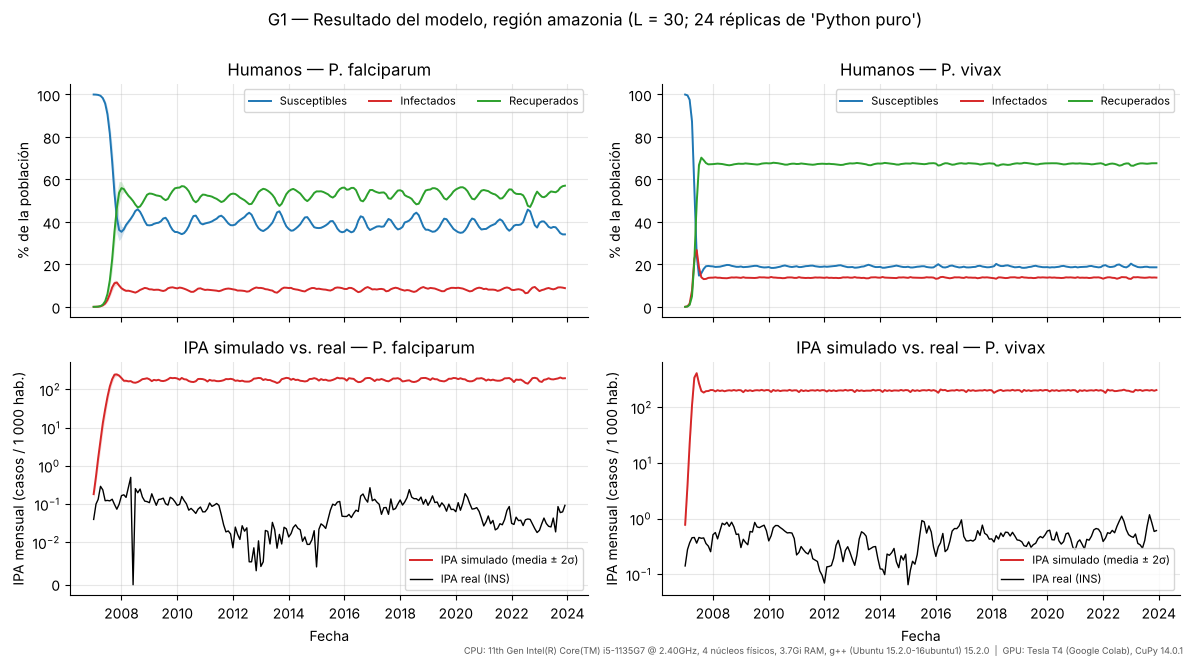

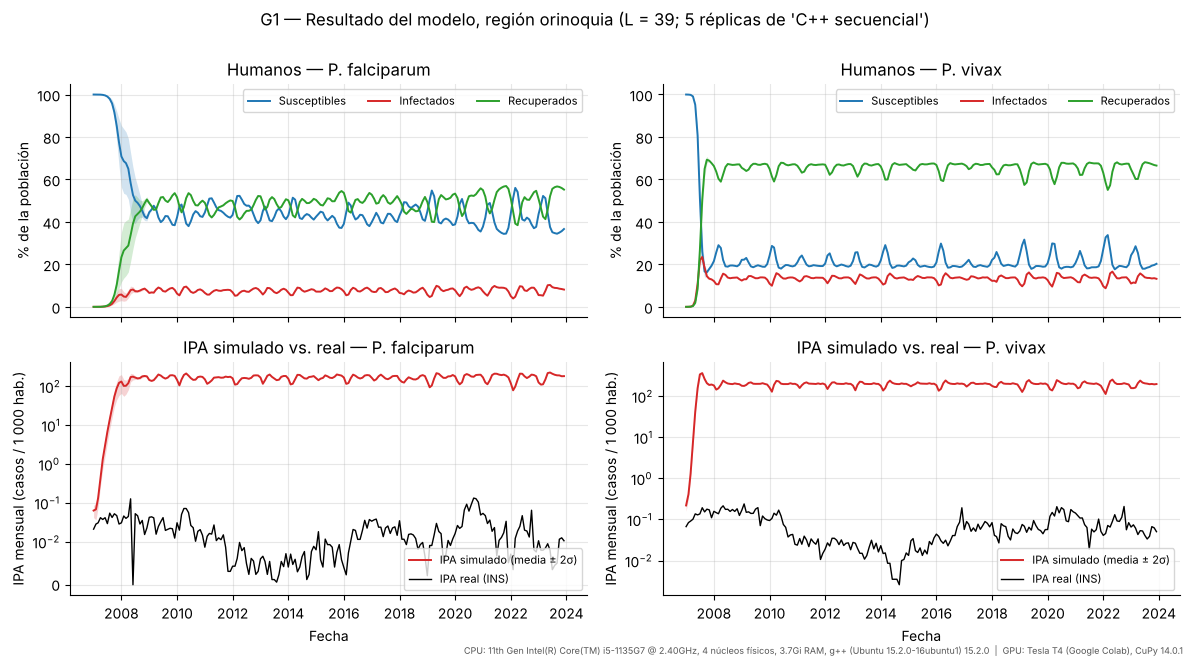

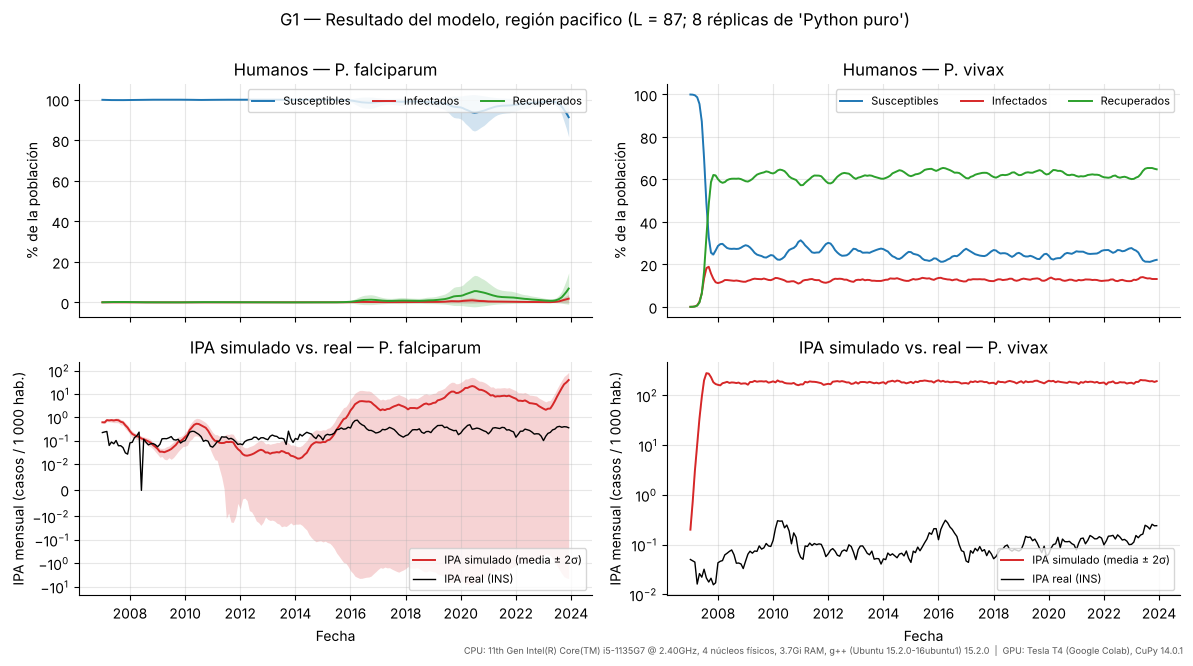

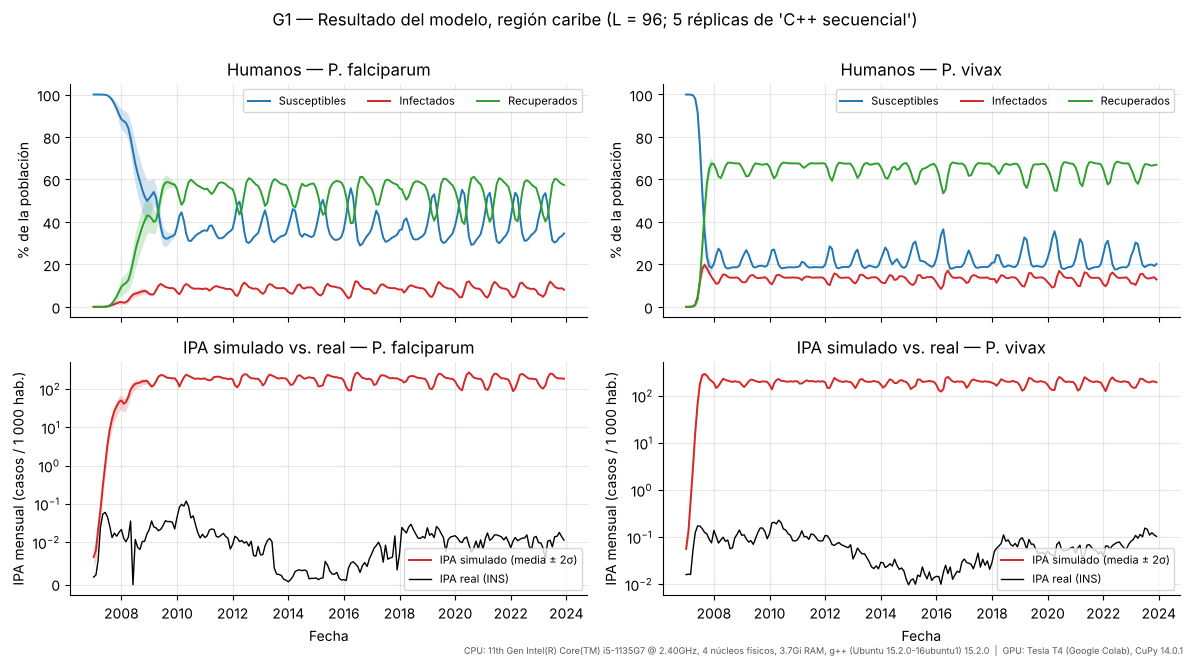

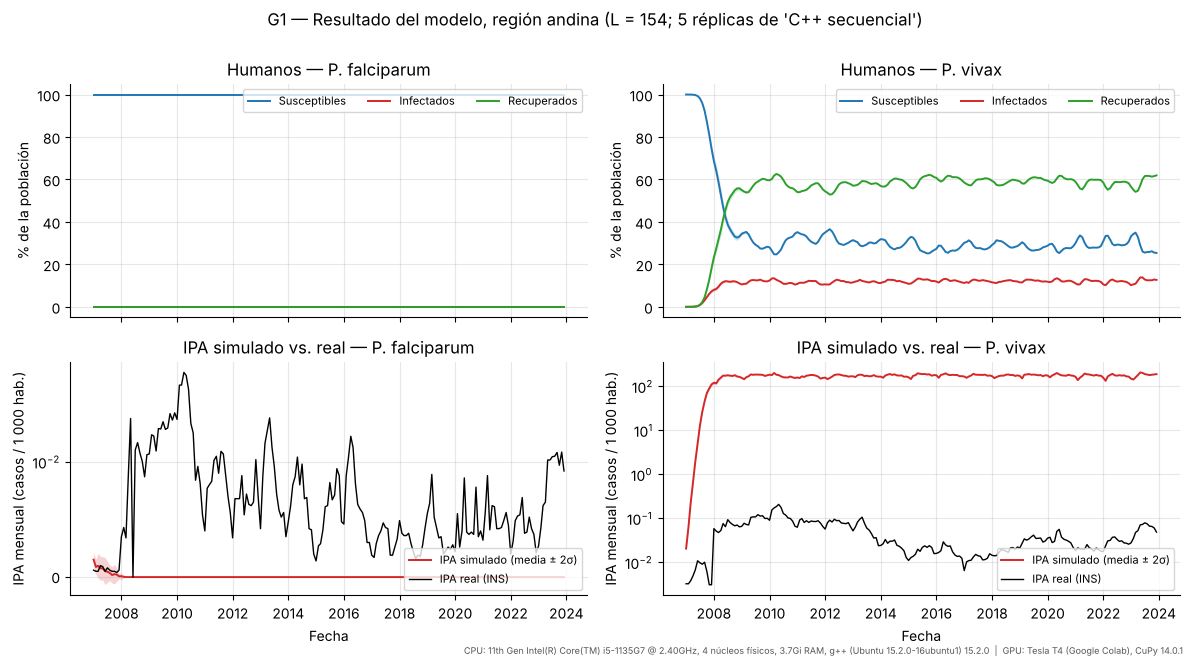

In [4]:
def banda(ax, x, M, c, lab, escala=1.0, ls="-"):
    mu, sd = M.mean(axis=0) * escala, (M.std(axis=0, ddof=1) if len(M) > 1 else np.zeros(M.shape[1])) * escala
    ax.plot(x, mu, color=c, lw=1.4, label=lab, ls=ls)
    ax.fill_between(x, mu - 2 * sd, mu + 2 * sd, color=c, alpha=0.2, lw=0)

for region in REGIONES_METRICAS:
    ref = referencia(region)
    x, L = fechas(region), BOARD_SIZE[region]
    n = len(RUNS[(ref, region)])
    fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
    for j, cepa in enumerate(("falciparum", "vivax")):
        ax = axes[0, j]
        for comp, c, lab in (("S_h", "#1f77b4", "Susceptibles"), ("I_h", "#d62728", "Infectados"), ("R_h", "#2ca02c", "Recuperados")):
            banda(ax, x, apilar(ref, region, f"{cepa}_{comp}"), c, lab, escala=100.0 / (L * L * 1000))
        ax.set_title(f"Humanos — P. {cepa}")
        ax.set_ylabel("% de la población")
        ax.legend(fontsize=8, ncol=3, loc="upper right")
        ax = axes[1, j]
        banda(ax, x, apilar(ref, region, f"IPA_{cepa}_simulado"), "#d62728", "IPA simulado (media ± 2σ)")
        ax.plot(x, RUNS[(ref, region)][0][f"IPA_{cepa}_real"], color="black", lw=1.0, label="IPA real (INS)")
        ax.set_yscale("symlog", linthresh=1e-2)
        ax.set_ylabel("IPA mensual (casos / 1 000 hab.)")
        ax.set_xlabel("Fecha")
        ax.set_title(f"IPA simulado vs. real — P. {cepa}")
        ax.legend(fontsize=8, loc="lower right")
    fig.suptitle(f"G1 — Resultado del modelo, región {region} (L = {L}; {n} réplicas de '{label(ref)}')", y=1.0)
    fig.tight_layout()
    guardar(fig, f"G1_resultado_{region}.png")

## G2 — Validación entre implementaciones

Criterio estadístico (guía §5.7, `AGENTS.md` §9.2): la curva media de IPA de cada
implementación debe caer dentro de la banda μ ± 2σ de la referencia, y el tamaño epidémico
final medio debe coincidir dentro de 2 errores estándar combinados.

- Las versiones C++ (`serial`, `openmp`, `mpi`) usan el mismo flujo aleatorio por fila, por lo
  que producen **series idénticas** con la misma semilla (se verifica abajo); en la figura se
  dibuja solo `serial` en representación de las tres.

amazonia: serial vs openmp: IDÉNTICOS (5 réplicas)
amazonia: serial vs mpi: IDÉNTICOS (5 réplicas)
orinoquia: serial vs openmp: IDÉNTICOS (5 réplicas)
orinoquia: serial vs mpi: IDÉNTICOS (5 réplicas)
pacifico: serial vs openmp: IDÉNTICOS (5 réplicas)
pacifico: serial vs mpi: IDÉNTICOS (5 réplicas)
caribe: serial vs openmp: IDÉNTICOS (5 réplicas)
caribe: serial vs mpi: IDÉNTICOS (5 réplicas)
andina: serial vs openmp: IDÉNTICOS (5 réplicas)
andina: serial vs mpi: IDÉNTICOS (5 réplicas)


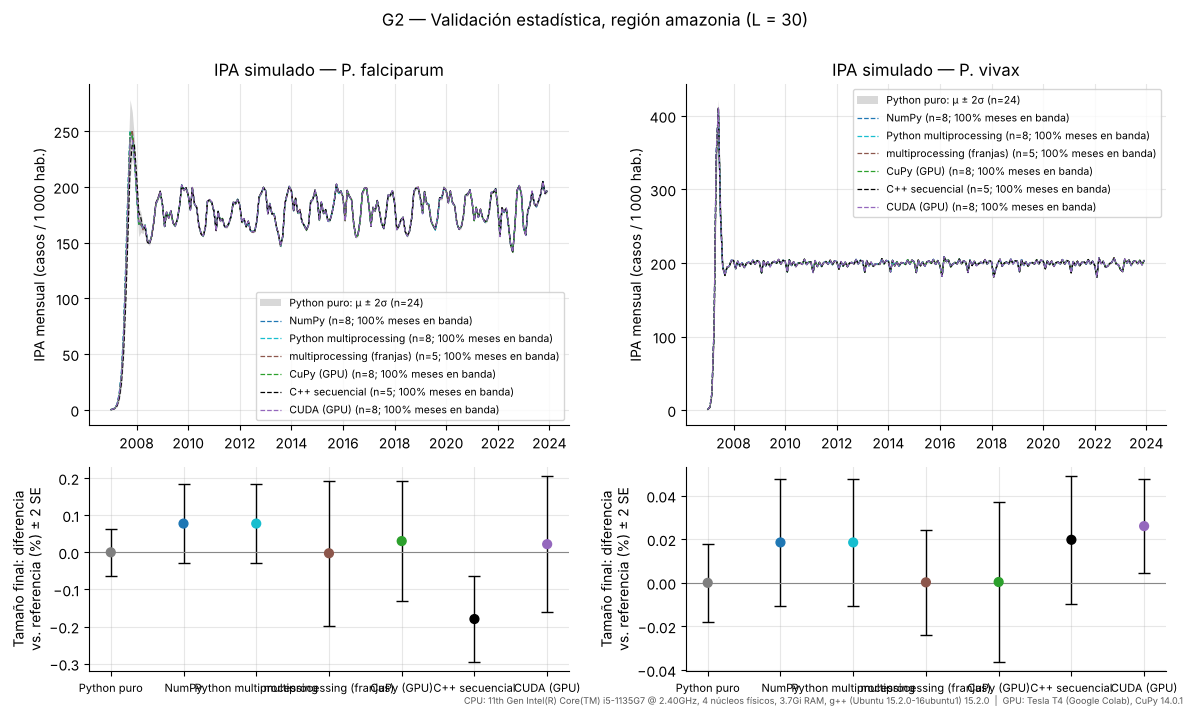

AVISO: G2: no hay réplicas de 'pure' para orinoquia (python tools/pure_replicas.py --region orinoquia); se omite


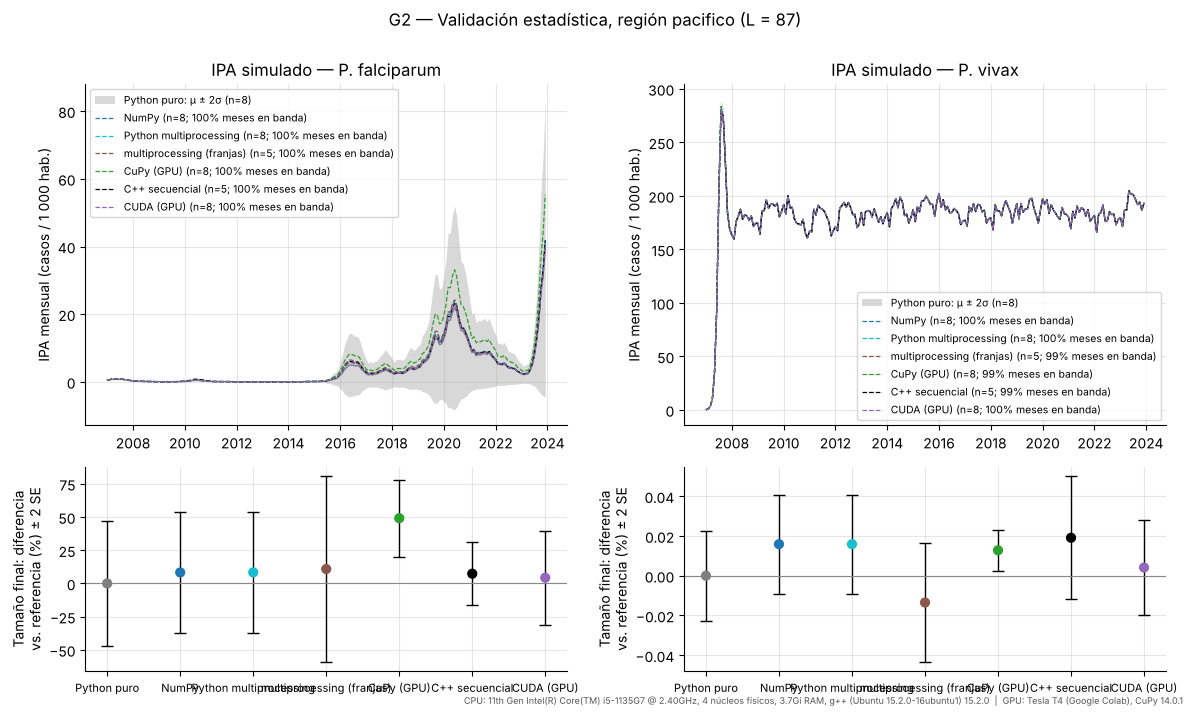

AVISO: G2: no hay réplicas de 'pure' para caribe (python tools/pure_replicas.py --region caribe); se omite
AVISO: G2: no hay réplicas de 'pure' para andina (python tools/pure_replicas.py --region andina); se omite


,region,cepa,paradigma,n,n_ref,C_final,C_final_ref,dif_relativa_%,|dif|,tolerancia_2SE,cumple_2SE,%_meses_en_banda
0,amazonia,falciparum,numpy,8,24,31915687.000,31891020.542,0.077,24666.458,39574.683,True,100.000
1,amazonia,falciparum,multiprocessing,8,24,31915687.000,31891020.542,0.077,24666.458,39574.683,True,100.000
2,amazonia,falciparum,multiprocessing_franjas,5,24,31890220.600,31891020.542,-0.003,799.942,65616.095,True,99.510
3,amazonia,falciparum,cupy,8,24,31900670.750,31891020.542,0.030,9650.208,55081.666,True,100.000
4,amazonia,falciparum,serial,5,24,31833734.400,31891020.542,-0.180,57286.142,42127.617,False,100.000
5,amazonia,falciparum,cuda,8,24,31898016.500,31891020.542,0.022,6995.958,61940.137,True,100.000
6,amazonia,vivax,numpy,8,24,36363204.500,36356464.333,0.019,6740.167,12360.525,True,100.000
7,amazonia,vivax,multiprocessing,8,24,36363204.500,36356464.333,0.019,6740.167,12360.525,True,100.000
8,amazonia,vivax,multiprocessing_franjas,5,24,36356546.600,36356464.333,0.000,82.267,10939.771,True,99.510
9,amazonia,vivax,cupy,8,24,36356603.250,36356464.333,0.000,138.917,14841.764,True,100.000


In [5]:
# Verificación exacta: serial == openmp == mpi (misma semilla).
for region in REGIONES_METRICAS:
    a = RUNS.get(("serial", region))
    for p in ("openmp", "mpi"):
        b = RUNS.get((p, region))
        if a and b and len(a) == len(b):
            iguales = all(x.drop(columns="paradigm").equals(y.drop(columns="paradigm")) for x, y in zip(a, b))
            print(f"{region}: serial vs {p}: {'IDÉNTICOS' if iguales else 'DIFERENTES'} ({len(a)} réplicas)")

filas = []
for region in REGIONES_METRICAS:
    ref = "pure" if len(RUNS.get(("pure", region), [])) >= 2 else None
    if ref is None:
        aviso(f"G2: no hay réplicas de 'pure' para {region} (python tools/pure_replicas.py --region {region}); se omite")
        continue
    otros = [p for p in PARADIGMS if p not in (ref, "openmp", "mpi") and len(RUNS.get((p, region), [])) >= 2]
    if not otros:
        aviso(f"G2: no hay otros paradigmas con réplicas para {region}")
        continue
    x = fechas(region)
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), gridspec_kw={"height_ratios": [2, 1.2]})
    for j, cepa in enumerate(("falciparum", "vivax")):
        ax = axes[0, j]
        R = apilar(ref, region, f"IPA_{cepa}_simulado")
        mu, sd = R.mean(axis=0), R.std(axis=0, ddof=1)
        ax.fill_between(x, mu - 2 * sd, mu + 2 * sd, color=color(ref), alpha=0.3, lw=0, label=f"{label(ref)}: μ ± 2σ (n={len(R)})")
        ax.plot(x, mu, color=color(ref), lw=1.0)
        Cref = apilar(ref, region, f"{cepa}_nuevos_casos_mes").sum(axis=1)
        barras = [(label(ref), Cref.mean(), Cref.std(ddof=1) / np.sqrt(len(Cref)), color(ref))]
        for p in otros:
            M = apilar(p, region, f"IPA_{cepa}_simulado")
            m = M.mean(axis=0)
            dentro = np.mean(np.abs(m - mu) <= 2 * sd + 1e-12)
            ax.plot(x, m, color=color(p), lw=0.9, ls="--", label=f"{label(p)} (n={len(M)}; {100 * dentro:.0f}% meses en banda)")
            C = M.sum(axis=1) * BOARD_SIZE[region] ** 2
            se = C.std(ddof=1) / np.sqrt(len(C))
            barras.append((label(p), C.mean(), se, color(p)))
            tol = 2 * np.hypot(se, barras[0][2])
            filas.append({"region": region, "cepa": cepa, "paradigma": p, "n": len(C), "n_ref": len(Cref),
                          "C_final": C.mean(), "C_final_ref": Cref.mean(), "dif_relativa_%": 100 * (C.mean() - Cref.mean()) / Cref.mean() if Cref.mean() else np.nan,
                          "|dif|": abs(C.mean() - Cref.mean()), "tolerancia_2SE": tol, "cumple_2SE": abs(C.mean() - Cref.mean()) <= tol,
                          "%_meses_en_banda": 100 * dentro})
        ax.set_title(f"IPA simulado — P. {cepa}")
        ax.set_ylabel("IPA mensual (casos / 1 000 hab.)")
        ax.legend(fontsize=7.5)
        ax = axes[1, j]
        base = barras[0][1] if barras[0][1] else 1.0
        ax.errorbar([b[0] for b in barras], [100 * (b[1] - base) / base for b in barras],
                    yerr=[200 * b[2] / base for b in barras], fmt="none", ecolor="black", capsize=4, lw=1)
        ax.scatter([b[0] for b in barras], [100 * (b[1] - base) / base for b in barras], c=[b[3] for b in barras], s=40, zorder=3)
        ax.axhline(0, color="#888888", lw=0.8)
        ax.set_ylabel("Tamaño final: diferencia\nvs. referencia (%) ± 2 SE")
        ax.tick_params(axis="x", labelsize=8)
    fig.suptitle(f"G2 — Validación estadística, región {region} (L = {BOARD_SIZE[region]})", y=1.0)
    fig.tight_layout()
    guardar(fig, f"G2_validacion_{region}.png")

if filas:
    validacion = pd.DataFrame(filas)
    validacion.to_csv(FIG / "tabla_validacion.csv", index=False)
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(validacion)

## G3 — Tiempo frente a tamaño (log-log)

Tiempo por simulación (mediana ± desviación estándar) frente al lado del tablero L. Para
los paradigmas paralelos se usa la mejor configuración sin sobresuscripción (workers ≤
núcleos físicos). El costo es O(L²) por paso, así que en log-log la pendiente esperada es 2
(línea punteada). Los puntos de **Python puro no medidos se extrapolan** con t = c·L² y se
dibujan huecos (guía §1.2 y G3).

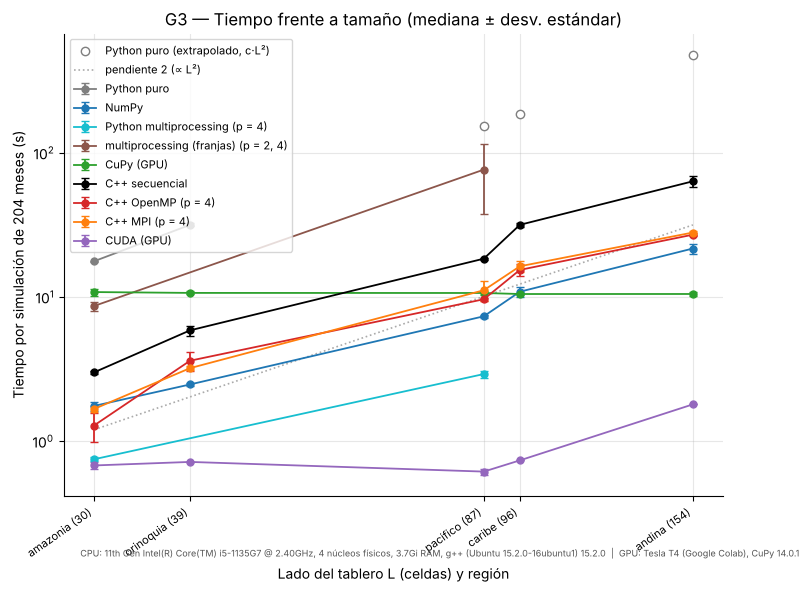

pendiente log-log NumPy                   : 1.54
pendiente log-log CuPy (GPU)              : -0.02
pendiente log-log C++ secuencial          : 1.82
pendiente log-log C++ OpenMP              : 1.76
pendiente log-log C++ MPI                 : 1.72
pendiente log-log CUDA (GPU)              : 0.42


In [6]:
def serie_tamano(p):
    # DataFrame con L, tiempo y std por región para un paradigma (mejor config. válida).
    out = []
    for r in REGIONS:
        b = mejor(p, r)
        if b:
            out.append({"region": r, "L": BOARD_SIZE[r], "workers": b[0], "t": b[1], "std": b[2]})
    return pd.DataFrame(out)

fig, ax = plt.subplots(figsize=(8.5, 6))
SERIES = {}
for p in presentes:
    s = serie_tamano(p)
    if s.empty:
        continue
    SERIES[p] = s
    w = sorted(set(s.workers))
    etiqueta = label(p) + ("" if w == [1] else f" (p = {', '.join(map(str, w))})")
    ax.errorbar(s.L, s.t, yerr=s["std"], color=color(p), marker="o", ms=5, lw=1.3, capsize=3, label=etiqueta)
    if p == "pure" and len(s) < len(REGIONS):
        c = np.mean(s.t / s.L ** 2)
        falt = [BOARD_SIZE[r] for r in REGIONS if r not in set(s.region)]
        ax.plot(falt, [c * L ** 2 for L in falt], ls="none", marker="o", ms=6, mfc="white", mec=color(p),
                label="Python puro (extrapolado, c·L²)")
        SERIES["pure_extrapolado"] = pd.DataFrame({"L": falt, "t": [c * L ** 2 for L in falt]})
Ls = np.array(sorted(BOARD_SIZE.values()), dtype=float)
if "serial" in SERIES:
    t0 = SERIES["serial"].t.iloc[0] / SERIES["serial"].L.iloc[0] ** 2
    ax.plot(Ls, 0.4 * t0 * Ls ** 2, color="#aaaaaa", ls=":", lw=1.2, label="pendiente 2 (∝ L²)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(Ls); ax.set_xticklabels([f"{r} ({int(L)})" for r, L in zip(REGIONS, Ls)], fontsize=8, rotation=35, ha="right")
ax.minorticks_off()
ax.set_xlabel("Lado del tablero L (celdas) y región")
ax.set_ylabel("Tiempo por simulación de 204 meses (s)")
ax.set_title("G3 — Tiempo frente a tamaño (mediana ± desv. estándar)")
ax.legend(fontsize=8)
guardar(fig, "G3_tiempo_vs_tamano.png")

# Pendientes ajustadas en log-log (deben ser cercanas a 2)
pend = []
for p, s in SERIES.items():
    if p != "pure_extrapolado" and len(s) >= 3:
        pend.append({"paradigma": p, "pendiente": np.polyfit(np.log(s.L), np.log(s.t), 1)[0], "regiones": len(s)})
        print(f"pendiente log-log {label(p):24s}: {pend[-1]['pendiente']:.2f}")
pd.DataFrame(pend, columns=["paradigma", "pendiente", "regiones"]).to_csv(FIG / "tabla_pendientes.csv", index=False)
pd.concat([s.assign(paradigma=p) for p, s in SERIES.items() if p != "pure_extrapolado"]).to_csv(FIG / "tabla_mejor_por_region.csv", index=False)

## G4 — Speedup frente a tamaño

Speedup de cada implementación respecto a las **dos referencias** de la guía (§6.5):
NumPy (ganancia práctica para un usuario de Python) y C++ secuencial (comparación justa
entre paradigmas).

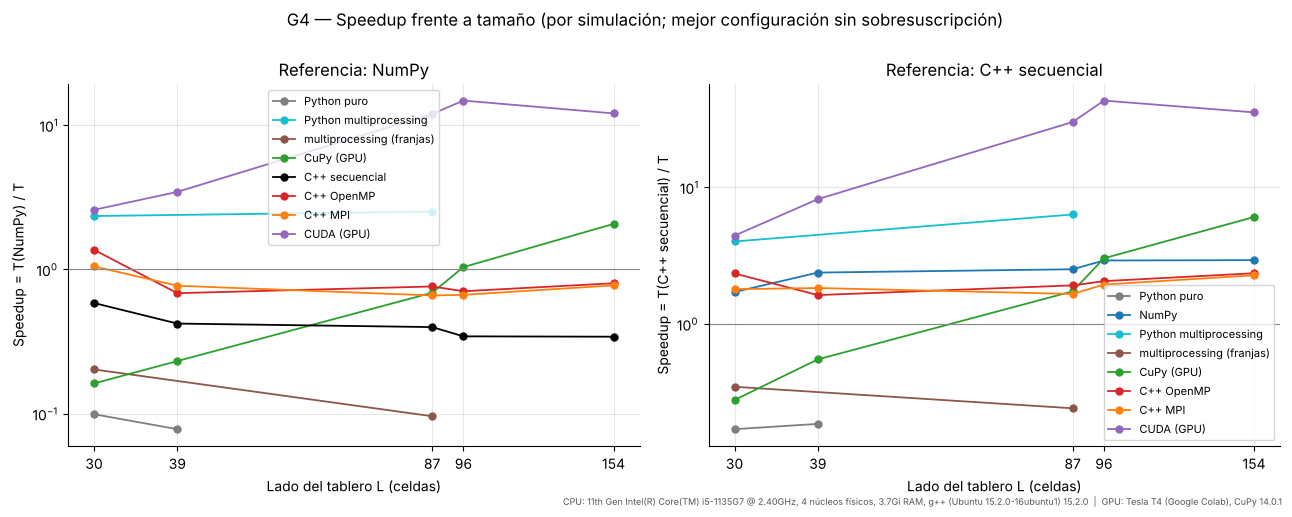

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, ref in zip(axes, ("numpy", "serial")):
    if ref not in SERIES:
        aviso(f"G4: no hay tiempos de '{ref}'; se omite el panel correspondiente")
        ax.set_visible(False)
        continue
    base = SERIES[ref].set_index("L").t
    for p, s in SERIES.items():
        if p in (ref, "pure_extrapolado"):
            continue
        s = s[s.L.isin(base.index)]
        if len(s):
            ax.plot(s.L, base.loc[s.L].to_numpy() / s.t.to_numpy(), marker="o", ms=5, lw=1.3, color=color(p), label=label(p))
    ax.axhline(1, color="#888888", lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(Ls); ax.set_xticklabels([f"{int(L)}" for L in Ls]); ax.minorticks_off()
    ax.set_xlabel("Lado del tablero L (celdas)")
    ax.set_ylabel(f"Speedup = T({label(ref)}) / T")
    ax.set_title(f"Referencia: {label(ref)}")
    ax.legend(fontsize=8)
fig.suptitle("G4 — Speedup frente a tamaño (por simulación; mejor configuración sin sobresuscripción)", y=1.0)
fig.tight_layout()
guardar(fig, "G4_speedup_vs_tamano.png")
if not ({"cupy", "cuda"} & set(SERIES)):
    aviso("G4: sin datos de GPU no se puede mostrar el tamaño de cruce GPU/CPU (ejecute colab/GPU_en_Colab.ipynb)")

## G5 — Escalabilidad fuerte: tiempo, speedup y eficiencia frente a workers

Tamaño fijo (una región) y número creciente de hilos (OpenMP) o procesos (MPI,
multiprocessing).

- **Referencia T₁:** C++ secuencial para OpenMP y MPI; para `multiprocessing`, el mismo lote
  de R réplicas con 1 proceso (definición documentada en `python/README.md`); para
  `multiprocessing (franjas)`, la misma simulación con 1 proceso.
- **Amdahl:** se ajusta f (fracción paralela) en S(p) = 1 / [(1 − f) + f/p] por mínimos
  cuadrados, usando solo los puntos con p ≤ núcleos físicos.
- **Karp–Flatt:** e = (1/S − 1/p) / (1 − 1/p). Si e crece con p, la pérdida viene de
  sobrecostos de paralelización y no solo de la parte serial.
- Los puntos con p > núcleos físicos (sobresuscripción) se dibujan huecos y no entran al ajuste.

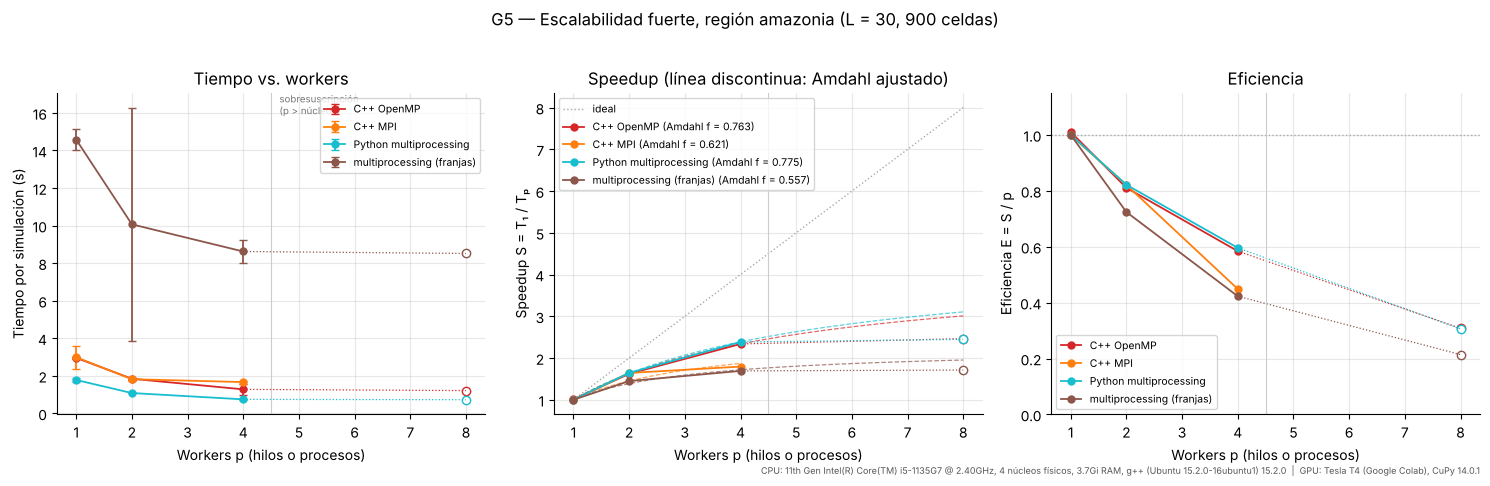

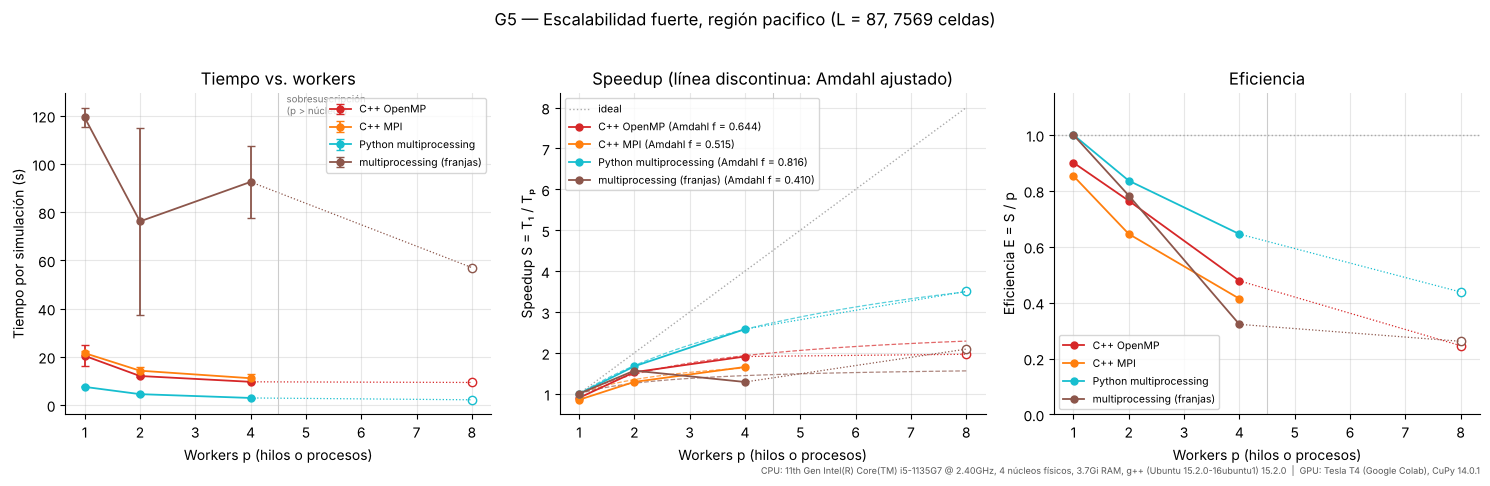

,region,paradigma,workers,T (s),speedup,eficiencia,karp_flatt,amdahl_f,sobresuscrito
0,amazonia,openmp,1,2.956,1.010,1.010,NaN,0.763,False
1,amazonia,openmp,2,1.842,1.622,0.811,0.233,0.763,False
2,amazonia,openmp,4,1.278,2.337,0.584,0.237,0.763,False
3,amazonia,openmp,8,1.212,2.465,0.308,0.321,0.763,True
4,amazonia,mpi,1,2.989,0.999,0.999,NaN,0.621,False
5,amazonia,mpi,2,1.819,1.642,0.821,0.218,0.621,False
6,amazonia,mpi,4,1.664,1.794,0.449,0.410,0.621,False
7,amazonia,multiprocessing,1,1.777,1.000,1.000,NaN,0.775,False
8,amazonia,multiprocessing,2,1.081,1.643,0.822,0.217,0.775,False
9,amazonia,multiprocessing,4,0.745,2.384,0.596,0.226,0.775,False


In [8]:
def ajustar_amdahl(p, S):
    f = np.linspace(0, 1, 100001)
    err = sum((1.0 / ((1 - f) + f / pi) - Si) ** 2 for pi, Si in zip(p, S))
    return float(f[np.argmin(err)])

tabla_esc = []
PAR = [p for p in ("openmp", "mpi", "multiprocessing", "multiprocessing_franjas") if p in presentes]
regiones_esc = [r for r in REGIONS if any(len(resumen[(resumen.paradigm == p) & (resumen.region == r)]) >= 2 for p in PAR)]
if not regiones_esc:
    aviso("G5: no hay configuraciones con varios workers")
for region in regiones_esc:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    pmax = 1
    for p in PAR:
        q = resumen[(resumen.paradigm == p) & (resumen.region == region)].sort_values("workers")
        if len(q) < 2:
            continue
        T1 = med("serial", region) if p in ("openmp", "mpi") else med(p, region, 1)
        if np.isnan(T1):
            T1 = med(p, region, 1)
        if np.isnan(T1):
            aviso(f"G5: falta la referencia T1 de {p} en {region}")
            continue
        w, t, sd = q.workers.to_numpy(), q.t_sim_mediana.to_numpy(), q.t_sim_std.fillna(0).to_numpy()
        S, E = T1 / t, T1 / t / w
        ok = (w <= N_CORES) if N_CORES else np.ones(len(w), bool)
        pmax = max(pmax, w.max())
        f = ajustar_amdahl(w[ok & (w > 1)], S[ok & (w > 1)]) if (ok & (w > 1)).sum() >= 1 else np.nan
        for ax, y, yerr in ((axes[0], t, sd), (axes[1], S, None), (axes[2], E, None)):
            ax.errorbar(w[ok], y[ok], yerr=None if yerr is None else yerr[ok], color=color(p), marker="o", ms=5, lw=1.3,
                        capsize=3, label=label(p) + (f" (Amdahl f = {f:.3f})" if ax is axes[1] and not np.isnan(f) else ""))
            if (~ok).any():
                ax.plot(w[~ok], y[~ok], ls="none", marker="o", ms=6, mfc="white", mec=color(p))
                i0 = np.where(ok)[0][-1]
                ax.plot([w[i0], w[~ok][0]], [y[i0], y[~ok][0]], color=color(p), lw=0.9, ls=":")
        if not np.isnan(f):
            pp = np.linspace(1, w.max(), 100)
            axes[1].plot(pp, 1 / ((1 - f) + f / pp), color=color(p), lw=0.9, ls="--", alpha=0.7)
        for wi, ti, Si, Ei, oki in zip(w, t, S, E, ok):
            kf = (1 / Si - 1 / wi) / (1 - 1 / wi) if wi > 1 else np.nan
            tabla_esc.append({"region": region, "paradigma": p, "workers": int(wi), "T (s)": ti, "speedup": Si, "eficiencia": Ei,
                              "karp_flatt": kf, "amdahl_f": f, "sobresuscrito": not oki})
    pp = np.arange(1, pmax + 1)
    axes[1].plot(pp, pp, color="#aaaaaa", ls=":", lw=1, label="ideal")
    axes[2].axhline(1, color="#aaaaaa", ls=":", lw=1)
    if N_CORES and pmax > N_CORES:
        for ax in axes:
            ax.axvline(N_CORES + 0.5, color="#cccccc", lw=0.8)
        axes[0].text(N_CORES + 0.6, axes[0].get_ylim()[1], " sobresuscripción\n (p > núcleos)", fontsize=7, va="top", color="#777777")
    axes[0].set_ylabel("Tiempo por simulación (s)"); axes[0].set_title("Tiempo vs. workers")
    axes[1].set_ylabel("Speedup S = T₁ / Tₚ"); axes[1].set_title("Speedup (línea discontinua: Amdahl ajustado)")
    axes[2].set_ylabel("Eficiencia E = S / p"); axes[2].set_title("Eficiencia"); axes[2].set_ylim(0, 1.15)
    for ax in axes:
        ax.set_xlabel("Workers p (hilos o procesos)"); ax.set_xticks(pp); ax.legend(fontsize=7.5)
    fig.suptitle(f"G5 — Escalabilidad fuerte, región {region} (L = {BOARD_SIZE[region]}, {BOARD_SIZE[region] ** 2} celdas)", y=1.02)
    fig.tight_layout()
    guardar(fig, f"G5_escalabilidad_fuerte_{region}.png")

if tabla_esc:
    escalabilidad = pd.DataFrame(tabla_esc)
    escalabilidad.to_csv(FIG / "tabla_escalabilidad.csv", index=False)
    with pd.option_context("display.float_format", "{:.3f}".format, "display.max_rows", 200):
        display(escalabilidad)

## G6 — Escalabilidad débil (MPI)

El tamaño del problema crece proporcionalmente al número de procesos (celdas por proceso
≈ constante). Se generan con el argumento experimental `--board-size` de `cpp/mpi`
(ver `tools/benchmark_weak.sh`), en `outputs/experiments/weak/times.csv`.

- Eficiencia débil: E = T(1, N) / T(p, p·N); ideal = 1.
- Speedup escalado frente a **Gustafson**: S(p) = (1 − f) + f·p, con la f de Amdahl de G5.

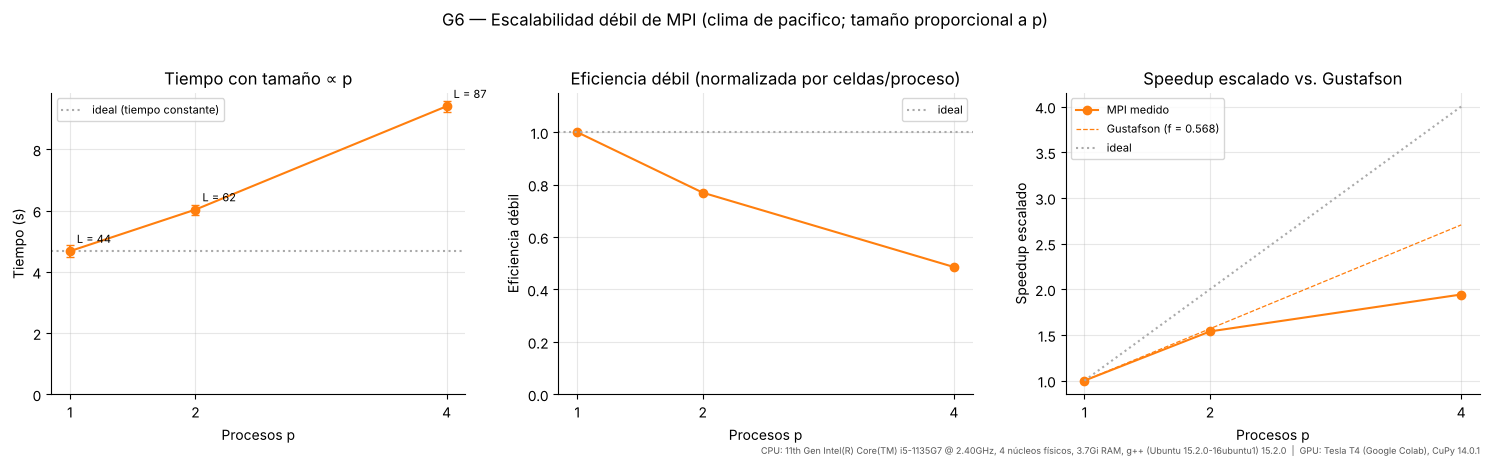

,workers,board_size,median,std,size,celdas_por_proceso,eficiencia_debil,speedup_escalado
0,1,44,4.673940,0.203837,5,1936.00,1.000000,1.000000
1,2,62,6.032016,0.161357,5,1922.00,0.769252,1.538504
2,4,87,9.406899,0.181851,5,1892.25,0.485635,1.942539


In [9]:
weak_path = OUT / "experiments" / "weak" / "times.csv"
if not weak_path.exists():
    aviso("G6: falta outputs/experiments/weak/times.csv (bash tools/benchmark_weak.sh); se omite")
else:
    wk = pd.read_csv(weak_path)
    wk = wk[wk.paradigm == "mpi"].groupby(["workers", "board_size"]).elapsed_time.agg(["median", "std", "size"]).reset_index()
    wk["celdas_por_proceso"] = wk.board_size ** 2 / wk.workers
    T1 = wk.loc[wk.workers == 1, "median"].iloc[0]
    wk["eficiencia_debil"] = T1 / wk["median"] * (wk.celdas_por_proceso / wk.celdas_por_proceso.iloc[0])
    wk["speedup_escalado"] = wk.eficiencia_debil * wk.workers
    f_mpi = np.nan
    if tabla_esc:
        fm = pd.DataFrame(tabla_esc).query("paradigma == 'mpi'").amdahl_f.dropna()
        f_mpi = fm.mean() if len(fm) else np.nan
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    axes[0].errorbar(wk.workers, wk["median"], yerr=wk["std"], color=color("mpi"), marker="o", capsize=3)
    axes[0].axhline(T1, color="#aaaaaa", ls=":", label="ideal (tiempo constante)")
    for w, t, L in zip(wk.workers, wk["median"], wk.board_size):
        axes[0].annotate(f"L = {L}", (w, t), textcoords="offset points", xytext=(5, 6), fontsize=8)
    axes[0].set_ylabel("Tiempo (s)"); axes[0].set_title("Tiempo con tamaño ∝ p"); axes[0].set_ylim(0, None)
    axes[1].plot(wk.workers, wk.eficiencia_debil, color=color("mpi"), marker="o")
    axes[1].axhline(1, color="#aaaaaa", ls=":", label="ideal"); axes[1].set_ylim(0, 1.15)
    axes[1].set_ylabel("Eficiencia débil"); axes[1].set_title("Eficiencia débil (normalizada por celdas/proceso)")
    axes[2].plot(wk.workers, wk.speedup_escalado, color=color("mpi"), marker="o", label="MPI medido")
    pp = np.linspace(1, wk.workers.max(), 50)
    if not np.isnan(f_mpi):
        axes[2].plot(pp, (1 - f_mpi) + f_mpi * pp, color=color("mpi"), ls="--", lw=0.9, label=f"Gustafson (f = {f_mpi:.3f})")
    axes[2].plot(pp, pp, color="#aaaaaa", ls=":", label="ideal")
    axes[2].set_ylabel("Speedup escalado"); axes[2].set_title("Speedup escalado vs. Gustafson")
    for ax in axes:
        ax.set_xlabel("Procesos p"); ax.set_xticks(wk.workers); ax.legend(fontsize=8)
    fig.suptitle("G6 — Escalabilidad débil de MPI (clima de pacifico; tamaño proporcional a p)", y=1.02)
    fig.tight_layout()
    guardar(fig, "G6_escalabilidad_debil.png")
    wk.to_csv(FIG / "tabla_escalabilidad_debil.csv", index=False)
    display(wk)

## G7 — Desglose del tiempo en GPU

Barras apiladas: copia a la GPU, cómputo y copia de vuelta, para varios tamaños (guía §6.2,
§6.4). Requiere `outputs/times_gpu.csv` con columnas
`paradigm, region, board_size, t_h2d, t_compute, t_d2h`, que genera `colab/GPU_en_Colab.ipynb`
en `outputs/gpu/`.

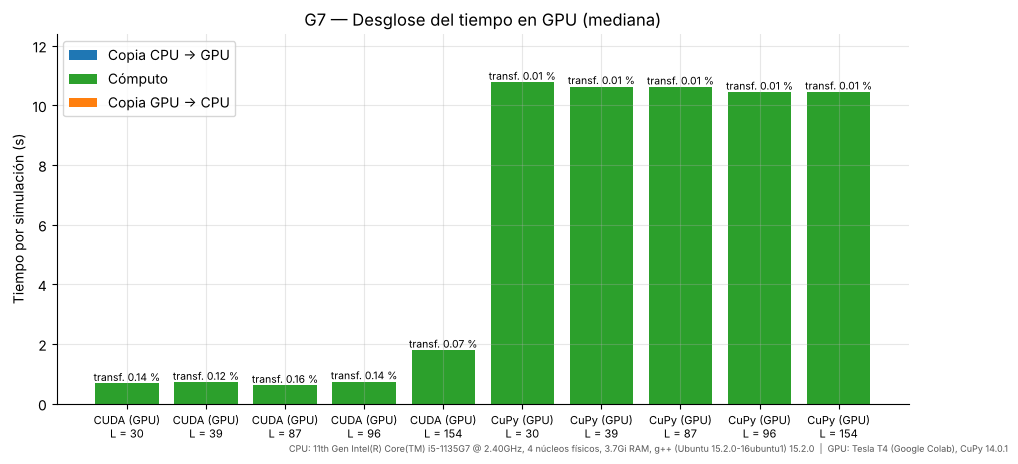

,paradigm,board_size,t_h2d,t_compute,t_d2h,fraccion_transferencia
0,cuda,30,0.000597,0.675162,0.000334,0.001377
1,cuda,39,0.000549,0.714451,0.000315,0.001207
2,cuda,87,0.000593,0.612170,0.000387,0.001599
3,cuda,96,0.000624,0.732356,0.000417,0.001420
4,cuda,154,0.000672,1.791683,0.000618,0.000719
5,cupy,30,0.000495,10.772093,0.000254,0.000070
6,cupy,39,0.000532,10.626453,0.000278,0.000076
7,cupy,87,0.000495,10.613439,0.000333,0.000078
8,cupy,96,0.000509,10.440241,0.000357,0.000083
9,cupy,154,0.000519,10.445434,0.000504,0.000098


In [10]:
gpu_path = GPU / "times_gpu.csv"
if not gpu_path.exists():
    aviso("G7: falta outputs/gpu/times_gpu.csv (ejecute colab/GPU_en_Colab.ipynb y copie outputs/gpu); se omite")
else:
    g = pd.read_csv(gpu_path).groupby(["paradigm", "board_size"])[["t_h2d", "t_compute", "t_d2h"]].median().reset_index()
    g = g.sort_values(["paradigm", "board_size"])
    fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(g) + 2), 4.8))
    xlab = [f"{label(p)}\nL = {L}" for p, L in zip(g.paradigm, g.board_size)]
    base = np.zeros(len(g))
    for col, lab, c in (("t_h2d", "Copia CPU → GPU", "#1f77b4"), ("t_compute", "Cómputo", "#2ca02c"), ("t_d2h", "Copia GPU → CPU", "#ff7f0e")):
        ax.bar(xlab, g[col], bottom=base, label=lab, color=c)
        base += g[col].to_numpy()
    tot = (g.t_h2d + g.t_compute + g.t_d2h).to_numpy()
    for x, (tt, fr) in enumerate(zip(tot, (g.t_h2d + g.t_d2h).to_numpy() / tot)):
        ax.text(x, tt, f"transf. {100 * fr:.2f} %", ha="center", va="bottom", fontsize=7.5)
    ax.set_ylim(0, tot.max() * 1.15)
    ax.set_ylabel("Tiempo por simulación (s)"); ax.set_title("G7 — Desglose del tiempo en GPU (mediana)")
    ax.legend(); ax.tick_params(axis="x", labelsize=8)
    guardar(fig, "G7_desglose_gpu.png")
    g["fraccion_transferencia"] = (g.t_h2d + g.t_d2h) / (g.t_h2d + g.t_compute + g.t_d2h)
    g.to_csv(FIG / "tabla_gpu.csv", index=False)
    display(g)

## P1 — Comparación entre paradigmas por región

Tiempo por simulación de cada paradigma (mejor configuración sin sobresuscripción) en
cada región, en escala logarítmica.

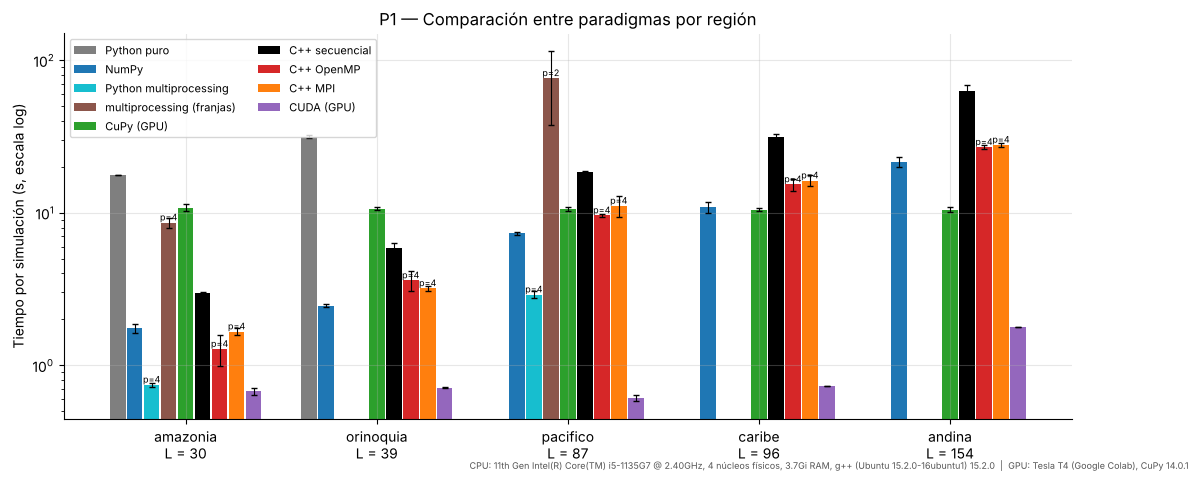

In [11]:
ps = [p for p in presentes if p in SERIES]
regs = [r for r in REGIONS if any(r in set(SERIES[p].region) for p in ps)]
fig, ax = plt.subplots(figsize=(max(8, 2.2 * len(regs) + 2), 5))
ancho = 0.8 / max(1, len(ps))
for i, p in enumerate(ps):
    s = SERIES[p].set_index("region")
    xs = [j + i * ancho for j, r in enumerate(regs) if r in s.index]
    ys = [s.loc[r, "t"] for r in regs if r in s.index]
    es = [s.loc[r, "std"] for r in regs if r in s.index]
    ax.bar(xs, ys, ancho * 0.92, yerr=es, color=color(p), label=label(p), capsize=2, error_kw={"lw": 0.8})
    for x, r in zip(xs, [r for r in regs if r in s.index]):
        if s.loc[r, "workers"] > 1:
            ax.text(x, s.loc[r, "t"], f"p={int(s.loc[r, 'workers'])}", ha="center", va="bottom", fontsize=6.5)
ax.set_yscale("log")
ax.set_xticks([j + ancho * (len(ps) - 1) / 2 for j in range(len(regs))])
ax.set_xticklabels([f"{r}\nL = {BOARD_SIZE[r]}" for r in regs])
ax.set_ylabel("Tiempo por simulación (s, escala log)")
ax.set_title("P1 — Comparación entre paradigmas por región")
ax.legend(fontsize=8, ncol=2)
guardar(fig, "P1_paradigmas_por_region.png")

## P2 — Rendimiento del problema: actualizaciones de celda por segundo

Métrica de rendimiento propia del proyecto (guía §5.8 y §6.5):
actualizaciones = L² × 204 meses × 4 sub-pasos × 2 cepas, dividido por el tiempo de una
simulación. Permite comparar tamaños distintos.

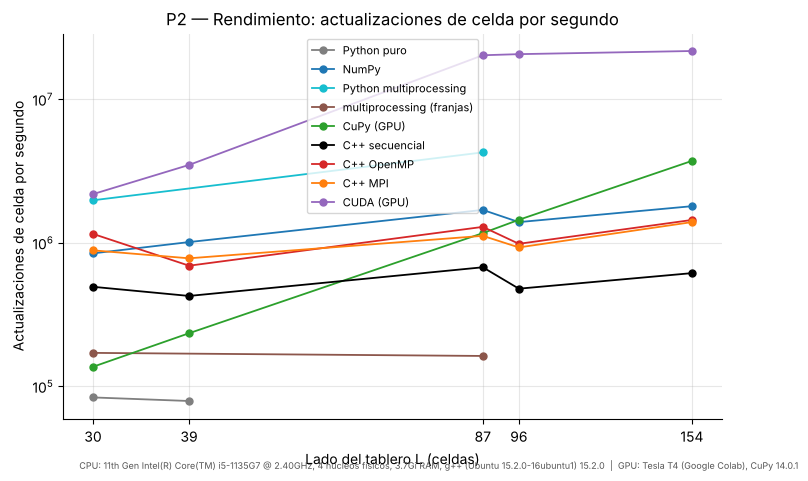

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5))
filas_ups = []
for p in ps:
    s = SERIES[p]
    ups = s.L ** 2 * ITERATIONS * SUBSTEPS * STRAINS / s.t
    ax.plot(s.L, ups, marker="o", ms=5, lw=1.3, color=color(p), label=label(p))
    filas_ups += [{"paradigma": p, "region": r, "L": L, "workers": w, "actualizaciones_por_s": u}
                  for r, L, w, u in zip(s.region, s.L, s.workers, ups)]
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(Ls); ax.set_xticklabels([f"{int(L)}" for L in Ls]); ax.minorticks_off()
ax.set_xlabel("Lado del tablero L (celdas)")
ax.set_ylabel("Actualizaciones de celda por segundo")
ax.set_title("P2 — Rendimiento: actualizaciones de celda por segundo")
ax.legend(fontsize=8)
guardar(fig, "P2_actualizaciones_por_segundo.png")
pd.DataFrame(filas_ups).to_csv(FIG / "tabla_actualizaciones_por_segundo.csv", index=False)

## P3 — Variabilidad entre réplicas cerca del umbral epidémico

Trayectorias individuales del IPA simulado de cada réplica (líneas finas) y su media (línea
gruesa), por implementación. Donde una especie está cerca del umbral epidémico, la epidemia
crece despacio y las réplicas divergen mucho: una sola realización no prueba nada (guía
§5.7). También deja ver si el muestreo aproximado de NumPy reproduce o no la dinámica de la
referencia exacta. La tabla reporta el coeficiente de variación (CV) del tamaño final y la
probabilidad de extinción (cero casos en los últimos 12 meses).

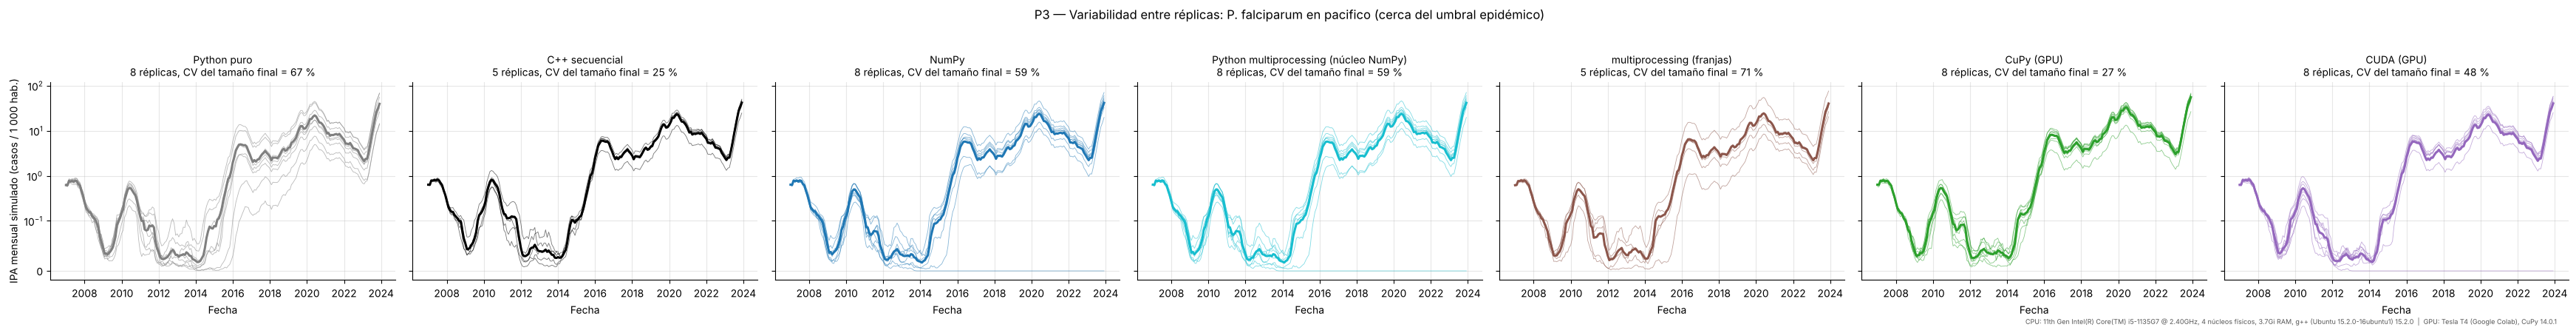

,region,paradigma,cepa,replicas,casos_acumulados_por_1000,cv_%,p_extincion
0,amazonia,cuda,falciparum,8,35442.24,0.26,0.00
10,amazonia,cupy,falciparum,8,35445.19,0.23,0.00
20,amazonia,multiprocessing,falciparum,8,35461.87,0.15,0.00
22,amazonia,multiprocessing_franjas,falciparum,5,35433.58,0.22,0.00
28,amazonia,numpy,falciparum,8,35461.87,0.15,0.00
38,amazonia,pure,falciparum,24,35434.47,0.16,0.00
42,amazonia,serial,falciparum,5,35370.82,0.13,0.00
1,amazonia,cuda,vivax,8,40406.59,0.03,0.00
11,amazonia,cupy,vivax,8,40396.23,0.05,0.00
21,amazonia,multiprocessing,vivax,8,40403.56,0.04,0.00


In [13]:
filas_var = []
for (p, region), runs in RUNS.items():
    if len(runs) < 2 or p in ("openmp", "mpi"):   # openmp/mpi son idénticas a serial
        continue
    for cepa in ("falciparum", "vivax"):
        C = np.array([r[f"{cepa}_nuevos_casos_mes"].sum() for r in runs], dtype=float) / BOARD_SIZE[region] ** 2
        filas_var.append({"region": region, "paradigma": p, "cepa": cepa, "replicas": len(runs),
                          "casos_acumulados_por_1000": C.mean(), "cv_%": 100 * C.std(ddof=1) / C.mean() if C.mean() else np.nan,
                          "p_extincion": np.mean([r[f"{cepa}_nuevos_casos_mes"].iloc[-12:].sum() == 0 for r in runs])})
if not filas_var:
    aviso("P3: no hay réplicas suficientes")
else:
    var = pd.DataFrame(filas_var)
    var.to_csv(FIG / "tabla_variabilidad.csv", index=False)
    # Caso más variable en la referencia disponible (el más cercano al umbral)
    cand = var[var.paradigma.isin(["pure", "serial"])].sort_values("cv_%", ascending=False).iloc[0]
    region, cepa = cand.region, cand.cepa
    ps3 = [p for p in ("pure", "serial", "numpy", "multiprocessing", "multiprocessing_franjas", "cupy", "cuda") if len(RUNS.get((p, region), [])) >= 2]
    fig, axes = plt.subplots(1, len(ps3), figsize=(5 * len(ps3), 4.2), sharey=True, squeeze=False)
    x = fechas(region)
    for ax, p in zip(axes[0], ps3):
        M = apilar(p, region, f"IPA_{cepa}_simulado")
        for fila in M:
            ax.plot(x, fila, color=color(p), lw=0.6, alpha=0.55)
        ax.plot(x, M.mean(axis=0), color=color(p), lw=2.2, label="media")
        ax.set_yscale("symlog", linthresh=0.1)
        cv = var[(var.region == region) & (var.paradigma == p) & (var.cepa == cepa)]["cv_%"].iloc[0]
        nota = " (núcleo NumPy)" if p == "multiprocessing" else ""
        ax.set_title(f"{label(p)}{nota}\n{len(M)} réplicas, CV del tamaño final = {cv:.0f} %", fontsize=10)
        ax.set_xlabel("Fecha")
    axes[0][0].set_ylabel("IPA mensual simulado (casos / 1 000 hab.)")
    fig.suptitle(f"P3 — Variabilidad entre réplicas: P. {cepa} en {region} (cerca del umbral epidémico)", y=1.03)
    fig.tight_layout()
    guardar(fig, "P3_variabilidad_replicas.png")
    with pd.option_context("display.float_format", "{:.2f}".format):
        display(var.sort_values(["region", "cepa", "paradigma"]))

## P4 — Decisión de implementación con más impacto (guía §6.7, pregunta 7)

**P4a. `lgamma` reentrante.** `std::binomial_distribution` llama a `lgamma()` de glibc, que
escribe la variable global `signgam`; con varios hilos esa línea de caché rebota entre
núcleos. Se comparan los tiempos de OpenMP antes
(`outputs/experiments/times_cpp_glibc_lgamma.csv`) y después (`outputs/times.csv`) de
sustituirla por `lgamma_r()`. MPI no se ve afectado porque cada proceso tiene su propia copia.

**P4b. Scheduling de OpenMP** (`static`, `dynamic`, `guided`), si existe
`outputs/experiments/schedule/times.csv` (ver `tools/benchmark_schedule.sh`).

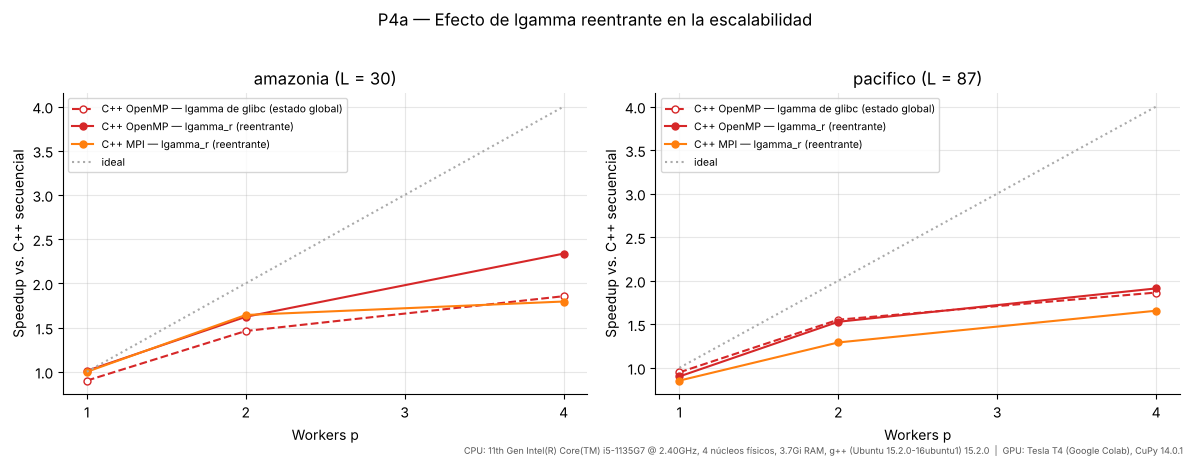

variante                    lgamma de glibc (estado global)  \
region   paradigma workers                                    
amazonia mpi       1                                    NaN   
                   2                                    NaN   
                   4                                    NaN   
         openmp    1                                   0.90   
                   2                                   1.46   
                   4                                   1.85   
pacifico mpi       1                                    NaN   
                   2                                    NaN   
                   4                                    NaN   
         openmp    1                                   0.95   
                   2                                   1.55   
                   4                                   1.86   

variante                    lgamma_r (reentrante)  
region   paradigma workers                         
amazonia mpi       1                         1.00  
                   2                         1.64  
                   4                         1.79  
         openmp    1                         1.01  
                   2                         1.62  
                   4                         2.34  
pacifico mpi       1                         0.85  
                   2                         1.29  
                   4                         1.66  
         openmp    1                         0.90  
                   2                         1.53  
                   4                         1.91

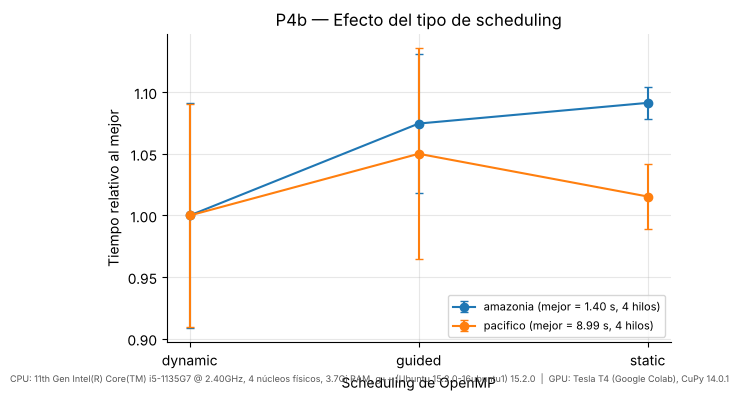

,region,schedule,median,std
0,amazonia,dynamic,1.3997,0.127908
1,amazonia,guided,1.5041,0.079245
2,amazonia,static,1.5276,0.018488
3,pacifico,dynamic,8.9886,0.810447
4,pacifico,guided,9.4386,0.770718
5,pacifico,static,9.1270,0.238208


In [14]:
antes_path = OUT / "experiments" / "times_cpp_glibc_lgamma.csv"
if not antes_path.exists():
    aviso("P4a: falta outputs/experiments/times_cpp_glibc_lgamma.csv; se omite")
else:
    antes = pd.read_csv(antes_path)
    regs4 = [r for r in REGIONS if r in set(antes[antes.paradigm == "openmp"].region)
             and r in set(times[times.paradigm == "openmp"].region)]
    fig, axes = plt.subplots(1, len(regs4), figsize=(6 * len(regs4), 4.4), squeeze=False)
    filas4 = []
    for ax, region in zip(axes[0], regs4):
        for df, lab, ls, mfc in ((antes, "lgamma de glibc (estado global)", "--", "white"), (times, "lgamma_r (reentrante)", "-", None)):
            for p in ("openmp", "mpi"):
                q = df[(df.paradigm == p) & (df.region == region)].groupby("workers").elapsed_time.median()
                s1 = df[(df.paradigm == "serial") & (df.region == region)].elapsed_time.median()
                if np.isnan(s1):  # el archivo "antes" puede traer solo OpenMP: se usa el serial actual
                    s1 = times[(times.paradigm == "serial") & (times.region == region)].elapsed_time.median()
                if q.empty:
                    continue
                if N_CORES:
                    q = q[q.index <= N_CORES]
                ax.plot(q.index, s1 / q.values, marker="o", ms=5, ls=ls, color=color(p), mfc=mfc or color(p), label=f"{label(p)} — {lab}")
                filas4 += [{"region": region, "paradigma": p, "variante": lab, "workers": int(w), "speedup": s1 / t} for w, t in q.items()]
        pp = np.arange(1, (N_CORES or 4) + 1)
        ax.plot(pp, pp, color="#aaaaaa", ls=":", label="ideal")
        ax.set_xticks(pp); ax.set_xlabel("Workers p"); ax.set_ylabel("Speedup vs. C++ secuencial")
        ax.set_title(f"{region} (L = {BOARD_SIZE[region]})"); ax.legend(fontsize=7.5)
    fig.suptitle("P4a — Efecto de lgamma reentrante en la escalabilidad", y=1.02)
    fig.tight_layout()
    guardar(fig, "P4a_lgamma.png")
    display(pd.DataFrame(filas4).pivot_table(index=["region", "paradigma", "workers"], columns="variante", values="speedup").round(2))

sch_path = OUT / "experiments" / "schedule" / "times.csv"
sch_log = OUT / "experiments" / "schedule" / "schedule.csv"
if not sch_log.exists():
    aviso("P4b: falta outputs/experiments/schedule/schedule.csv (bash tools/benchmark_schedule.sh); se omite")
else:
    sc = pd.read_csv(sch_log)
    g = sc.groupby(["region", "schedule"]).elapsed_time.agg(["median", "std"]).reset_index()
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for i, (region, q) in enumerate(g.groupby("region")):
        ax.errorbar(q.schedule, q["median"] / q["median"].min(), yerr=q["std"] / q["median"].min(), marker="o", capsize=3,
                    label=f"{region} (mejor = {q['median'].min():.2f} s, {int(sc.threads.iloc[0])} hilos)")
    ax.set_ylabel("Tiempo relativo al mejor"); ax.set_xlabel("Scheduling de OpenMP")
    ax.set_title("P4b — Efecto del tipo de scheduling"); ax.legend(fontsize=8)
    guardar(fig, "P4b_scheduling.png")
    display(g)

## Resumen de la ejecución

In [15]:
print(f"Figuras generadas en {FIG.relative_to(ROOT)}/ ({len(FIGURAS)}):")
for f in FIGURAS:
    print("  ", f)
print(f"\nAvisos ({len(AVISOS)}):")
for a in AVISOS:
    print("  -", a)

Figuras generadas en outputs/figures/ (18):
   G1_resultado_amazonia.png
   G1_resultado_orinoquia.png
   G1_resultado_pacifico.png
   G1_resultado_caribe.png
   G1_resultado_andina.png
   G2_validacion_amazonia.png
   G2_validacion_pacifico.png
   G3_tiempo_vs_tamano.png
   G4_speedup_vs_tamano.png
   G5_escalabilidad_fuerte_amazonia.png
   G5_escalabilidad_fuerte_pacifico.png
   G6_escalabilidad_debil.png
   G7_desglose_gpu.png
   P1_paradigmas_por_region.png
   P2_actualizaciones_por_segundo.png
   P3_variabilidad_replicas.png
   P4a_lgamma.png
   P4b_scheduling.png

Avisos (4):
  - 2 configuraciones tienen menos de 5 repeticiones (la guía pide al menos 5): pure/amazonia/p=1(n=3), pure/orinoquia/p=1(n=3)
  - G2: no hay réplicas de 'pure' para orinoquia (python tools/pure_replicas.py --region orinoquia); se omite
  - G2: no hay réplicas de 'pure' para caribe (python tools/pure_replicas.py --region caribe); se omite
  - G2: no hay réplicas de 'pure' para andina (python tools/pure_repl